In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report

In [22]:
# 1.Given a dataset diabetes.csv, write a Python script to load and display the dataset.
df = pd.read_csv('/content/diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [23]:
# 2.Rename the columns accordingly: ‘Pregnancies’ to ‘Pregnant’, ‘BloodPressure’ to ‘BP’, ‘SkinThickness’ to ‘Skin’ and ‘DiabetesPedigreeFunction’ to ‘Pedigree’ and display again.

df = df.rename(columns={'Pregnancies':'Pregnant',
                        'BloodPressure':'BP',
                        'SkinThickness':'skin',
                        'DiabetesPedigreeFunction':'Pedigree'})
print(df.head())

   Pregnant  Glucose  BP  skin  Insulin   BMI  Pedigree  Age  Outcome
0         6      148  72    35        0  33.6     0.627   50        1
1         1       85  66    29        0  26.6     0.351   31        0
2         8      183  64     0        0  23.3     0.672   32        1
3         1       89  66    23       94  28.1     0.167   21        0
4         0      137  40    35      168  43.1     2.288   33        1


In [24]:
# 3.Use the describe() function to print the statistical summary of the data in the dataframe.
df.describe()

,Pregnant,Glucose,BP,skin,Insulin,BMI,Pedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [25]:
# 4.Consider the ‘Pregnant’, ‘BP’, ‘Insulin’, ‘BMI’, ‘Pedigree’ and ‘Age’ to be the feature columns and split the dataset into 80% train and 20% test data.

x = df[['Pregnant', 'BP', 'Insulin', 'BMI', 'Pedigree', 'Age']]
print(df)
y = df['Outcome']

     Pregnant  Glucose  BP  skin  Insulin   BMI  Pedigree  Age  Outcome
0           6      148  72    35        0  33.6     0.627   50        1
1           1       85  66    29        0  26.6     0.351   31        0
2           8      183  64     0        0  23.3     0.672   32        1
3           1       89  66    23       94  28.1     0.167   21        0
4           0      137  40    35      168  43.1     2.288   33        1
..        ...      ...  ..   ...      ...   ...       ...  ...      ...
763        10      101  76    48      180  32.9     0.171   63        0
764         2      122  70    27        0  36.8     0.340   27        0
765         5      121  72    23      112  26.2     0.245   30        0
766         1      126  60     0        0  30.1     0.349   47        1
767         1       93  70    31        0  30.4     0.315   23        0

[768 rows x 9 columns]


In [29]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 6)
(154, 6)
(614,)
(154,)


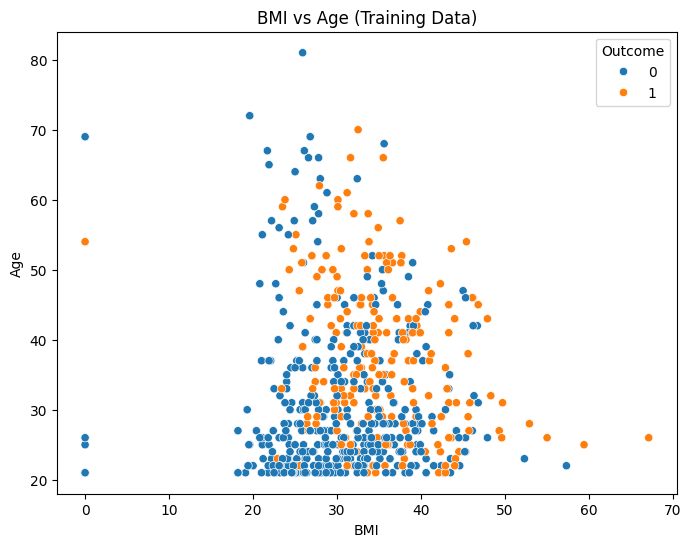

In [33]:
# 5.Create a scatterplot showing the relation between ‘BMI’ and ‘Age’ on the training data with ‘Outcome’ as hue.

plt.figure(figsize=(8,6))
sns.scatterplot(x=x_train['BMI'], y=x_train['Age'], hue=y_train,)
plt.title("BMI vs Age (Training Data)")
plt.xlabel("BMI")
plt.ylabel("Age")
plt.show()

In [40]:
# 6. Perform Standardization using StandardScaler.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

# Convert back to DataFrame for readability
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=x_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=x_test.columns)

print("\nStandardized Training Data (first 5 rows):\n")
print(X_train_scaled_df.head())


Standardized Training Data (first 5 rows):

   Pregnant        BP   Insulin       BMI  Pedigree       Age
0 -0.526397 -3.752683 -0.701206 -4.135256 -0.490735 -1.035940
1  1.588046  0.680345 -0.701206 -0.489169  2.415030  1.487101
2 -0.828460 -1.265862  0.013448 -0.424522  0.549161 -0.948939
3 -1.130523 -1.049617 -0.701206 -1.303720 -0.639291  2.792122
4  0.681856  0.572222  2.484601  1.838121 -0.686829  1.139095


In [61]:
# 7.Train a logistic regression model using an inbuilt function on train set.
log_reg = LogisticRegression(max_iter=5000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

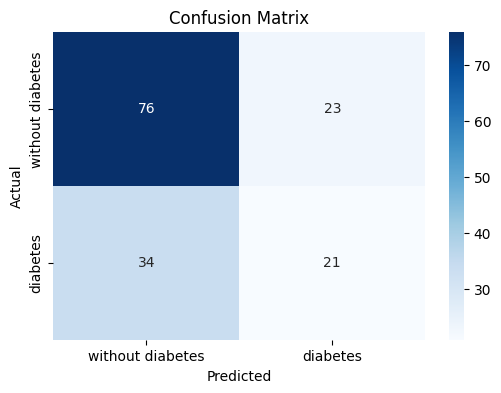

In [62]:
# 8.Calculate the confusion matrix and display it using heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap='Blues',
            xticklabels=['without diabetes', 'diabetes'],
            yticklabels=['without diabetes', 'diabetes'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [63]:
# 9.Calculate the accuracy and f1-score of the model using accuracy_score and f1_score respectively.
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nAccuracy:. ",acc)
print("F1 Score: ",f1)


Accuracy:.  0.6298701298701299
F1 Score:  0.42424242424242425


In [64]:
# 10.Print the classification report with the target names ‘with diabetes’ and ‘without diabetes’.
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['without diabetes', 'with diabetes']
))


Classification Report:
                  precision    recall  f1-score   support

without diabetes       0.69      0.77      0.73        99
   with diabetes       0.48      0.38      0.42        55

        accuracy                           0.63       154
       macro avg       0.58      0.57      0.58       154
    weighted avg       0.61      0.63      0.62       154

